In [1]:
from sklearn.datasets import load_breast_cancer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42


In [2]:
datos=load_breast_cancer(as_frame=True)
x=datos.data
y=datos.target
print(f'Total de observaciones:{x.shape[0]}|Variables:{x.shape[1]}')
print(f'Valores faltantes: {x.isna().sum()}')
print(f'variables: {dict(enumerate(datos.target_names))}')

Total de observaciones:569|Variables:30
Valores faltantes: mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
variables: {0: np.str_('malignant'), 1: np.str_('benign')}

actividad 2

           casos  porcentaje
malignant    212   37.258348
benign       357   62.741652
Exactitud de un modelo que responde siempre benign - 62.742


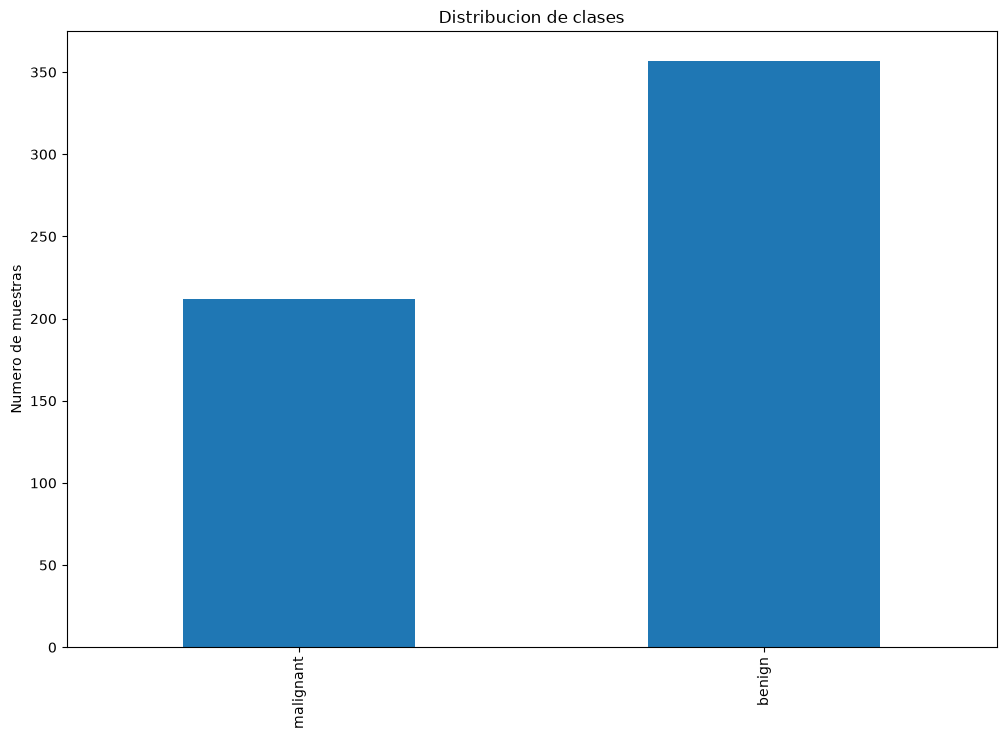

In [3]:
conteo=y.value_counts().sort_index()
conteo.index=datos.target_names
porcentaje=(conteo/conteo.sum())*100
resumen=pd.DataFrame({'casos':conteo,'porcentaje':porcentaje})
print(resumen)

mayoritaria=conteo.max()/conteo.sum()*100
print(f'Exactitud de un modelo que responde siempre {conteo.idxmax()} - {mayoritaria:.3f}')
conteo.plot(kind='bar', figsize=(12,8))
plt.ylabel('Numero de muestras')
plt.title('Distribucion de clases')
plt.show()

actividada 3

In [4]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test=train_test_split(
    x,y, test_size=0.2, stratify=y, random_state=   RANDOM_STATE
)

_, _, sin_y_train, sin_y_test=train_test_split(
    x,y, test_size=0.2, random_state=   RANDOM_STATE
)
comparador=pd.DataFrame({
    'conjunto completo':y.value_counts(normalize=True).sort_index(),
    'train (stratificado)':y_train.value_counts(normalize=True).sort_index(),
    'train (sin stratificado)':sin_y_train.value_counts(normalize=True).sort_index(),
    'test (stratificado)':y_test.value_counts(normalize=True).sort_index(),
    'test (sin stratificado)':sin_y_test.value_counts(normalize=True).sort_index()
})
comparador.index=datos.target_names
comparador.head(5)

,conjunto completo,train (stratificado),train (sin stratificado),test (stratificado),test (sin stratificado)
malignant,0.372583,0.373626,0.371429,0.368421,0.377193
benign,0.627417,0.626374,0.628571,0.631579,0.622807


In [5]:
x_train.shape
y_train.shape

(455,)

actividad 4

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

trivial=DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
trivial.fit(x_train, y_train)

pred_trivial=trivial.predict(x_test)

print(f'Exactitud:{accuracy_score(y_test, pred_trivial):.3f}')
print(f'Recall sobre la clase benigna (clase 1):{recall_score(y_test, pred_trivial, pos_label=1):.3f}')
print(f'Recall sobre la clase maligna (clase 0):{recall_score(y_test, pred_trivial, pos_label=0):.3f}')

Exactitud:0.632
Recall sobre la clase benigna (clase 1):1.000
Recall sobre la clase maligna (clase 0):0.000


In [7]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

def evaluar(modelo, nombre, x_test, y_test):
    preds=modelo.predict(x_test)
    return{
        'modelo':nombre,
        'exactitud':accuracy_score(y_test, preds),
        'precision':precision_score(y_test, preds),
        'recall':recall_score(y_test, preds),
        'f1':f1_score(y_test, preds),
        'auc': roc_auc_score(y_test, modelo.predict_proba(x_test)[:,1])

    }
resultados=[evaluar(trivial, 'Trivial', x_test, y_test)]
pd.DataFrame(resultados)

,modelo,exactitud,precision,recall,f1,auc
0,Trivial,0.631579,0.631579,1.0,0.774194,0.5


In [8]:
from sklearn.pipeline import  Pipeline, make_pipeline
from sklearn.preprocessing  import StandardScaler
from sklearn.linear_model import LogisticRegression
modelo=Pipeline([
    ('scaler',StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

])
modelo.fit(x_train, y_train)
metricas_escalando=evaluar(modelo,'logistic regresor con escalamiento', x_test, y_test)

modelo_sin_escalar=Pipeline([
    ('clf', LogisticRegression(max_iter=100, random_state=RANDOM_STATE))
])
modelo_sin_escalar.fit(x_train, y_train)
metricas_sin_escalar=evaluar(modelo_sin_escalar,'logistic regresor sin escalar', x_test, y_test)

print(f'Exactitud con escalamiento: {metricas_escalando['exactitud']:.3f}')
print(f'Exactitud sin escalamiento: {metricas_sin_escalar['exactitud']:.3f}')

print(f'Iteraciones usando escalamiento: {modelo['clf'].n_iter_}')
print(f'Iteraciones sin escalamiento: {modelo_sin_escalar['clf'].n_iter_}')

Exactitud con escalamiento: 0.982
Exactitud sin escalamiento: 0.947
Iteraciones usando escalamiento: [19]
Iteraciones sin escalamiento: [100]


c:\Users\HP\Documents\Data_Science\01-python-intro\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:
resultados.append(
    evaluar(modelo,'logistico', x_test, y_test)
)
comparativa=pd.DataFrame(resultados).set_index('modelo')
comparativa['recall_maligna']=[
    recall_score(y_test, trivial.predict(x_test), pos_label=0),
    recall_score(y_test, modelo.predict(x_test), pos_label=0)
]
mejora_exactitud=comparativa.loc['logistico','exactitud']-comparativa.loc['Trivial','exactitud']
mejora_recall=comparativa.loc['logistico','recall_maligna']-comparativa.loc['Trivial','recall_maligna']

print(f'Mejora de la exactitud: {mejora_exactitud:+.3f}')
print(f'Mejora de recall sobre casos malignos: {mejora_recall:+.3f}')

Mejora de la exactitud: +0.351
Mejora de recall sobre casos malignos: +0.976


In [10]:
comparativa

,exactitud,precision,recall,f1,auc,recall_maligna
modelo,,,,,,
Trivial,0.631579,0.631579,1.000000,0.774194,0.50000,0.00000
logistico,0.982456,0.986111,0.986111,0.986111,0.99537,0.97619


actividad 7

Casoscon probabilidad entre 0.4 y 0.6: 3
Casoscon probabilidad debajo de 0.0536
Casoscon probabilidad encima de 0.9554


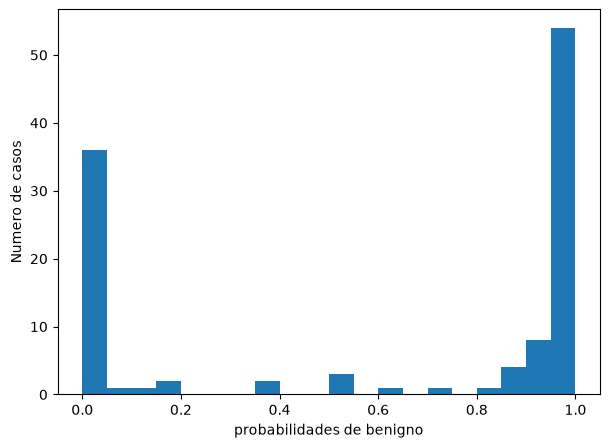

In [11]:
probabilidades=modelo.predict_proba(x_test)[:,1]
print(
    f'Casoscon probabilidad entre 0.4 y 0.6: {((probabilidades>0.4)&(probabilidades<0.6)).sum()}'
)
print(f'Casoscon probabilidad debajo de 0.05{(probabilidades<0.05).sum()}')
print(f'Casoscon probabilidad encima de 0.95{(probabilidades>0.95).sum()}')

plt.figure(figsize=(7,5))
plt.hist(probabilidades, bins=20)
plt.xlabel('probabilidades de benigno')
plt.ylabel('Numero de casos')
plt.show()

act 10

In [12]:
desicion_manual=(probabilidades>=0.5).astype(int)
desicion_sklearn=modelo.predict(x_test)
print(f'Coincide en todos los casos: {(desicion_manual==desicion_sklearn).all()}')
print(f'Casos en los que difiere: {(desicion_manual!=desicion_sklearn).sum()}')


Coincide en todos los casos: True
Casos en los que difiere: 0


actividad 9

In [13]:
prob_train=modelo.predict_proba(x_train)[:,1]
filas=[]
for umbral in np.arange(0.1,1.0, 0.1):
    pred_u=(prob_train>=umbral).astype(int)
    filas.append(
        'umbral':round(umbral,1),
        'marcados_positivos':int(pred_u.sum()),
        'presicion':presicion_score(y_train, pred_u),
        'recall':recall_score(y_train, u_pred)
    )

SyntaxError: invalid syntax (1520493189.py, line 6)

In [ ]:
probabilidades_maligno=modelo.predict_proba(x_test)[:,0]
y_maligno=(y_test==0).astype(int)
filas=[]
for umbral in np.arange(0.05, 0.96, 0.05):
    marcado=(probabilidades_maligno>=umbral).astype(int)
    m=confusion_matrix( )

16

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
filas=[]

knn=make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=10))

knn.fit(x_train, y_train)
resultados.append(evaluar(knn, 'KNN(10)', x_test, y_test))
pd.DataFrame(resultados)